In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import sys

def plot_temp_log(filepath):
    df = pd.read_csv(filepath, usecols=['value', 'created_at'])
    df['created_at'] = pd.to_datetime(df['created_at'], utc=True)
    df = df.sort_values('created_at')

    fig, ax = plt.subplots(figsize=(12, 4))
    ax.plot(df['created_at'], df['value'], lw=0.8, color='steelblue')
    ax.scatter(df['created_at'], df['value'], s=4, color='red')

    ax.set_xlabel('Time (UTC)')
    ax.set_ylabel('Temperature (°C)')
    ax.set_title(filepath.split('/')[-1].replace('.csv', ''))

    # Smart date formatting based on time span
    span = df['created_at'].iloc[-1] - df['created_at'].iloc[0]
    if span.days > 7:
        ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d'))
    elif span.days > 1:
        ax.xaxis.set_major_formatter(mdates.DateFormatter('%m-%d %H:%M'))
    else:
        ax.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))

    fig.autofmt_xdate()
    plt.tight_layout()
    plt.show()

# if __name__ == '__main__':
#     path = sys.argv[1] if len(sys.argv) > 1 else 'Nozzle_Temp_092025.csv'
#     plot_temp_log(path)

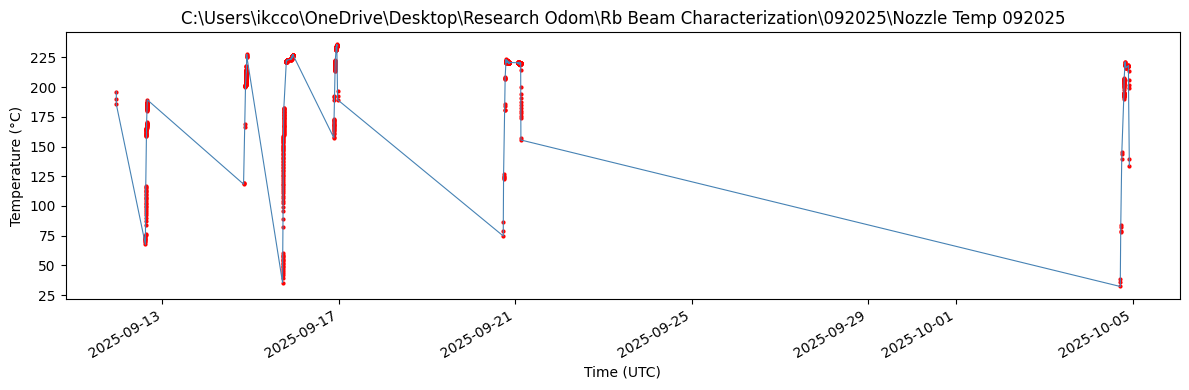

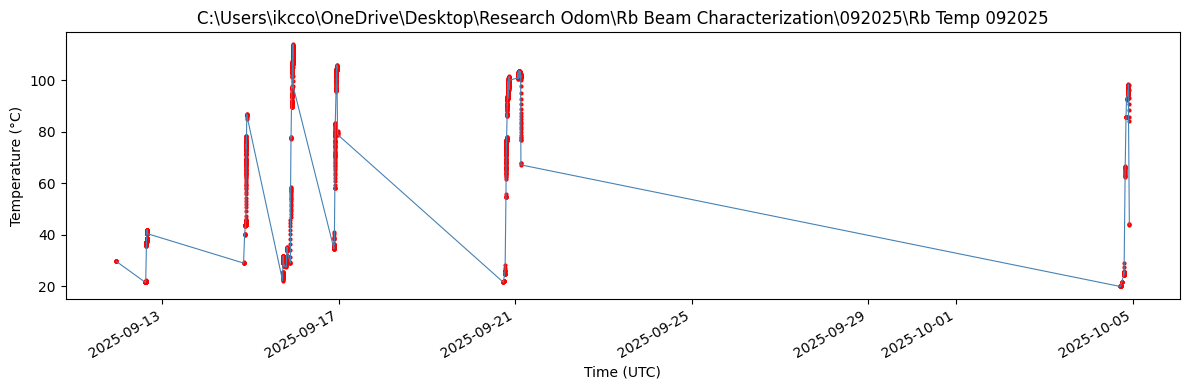

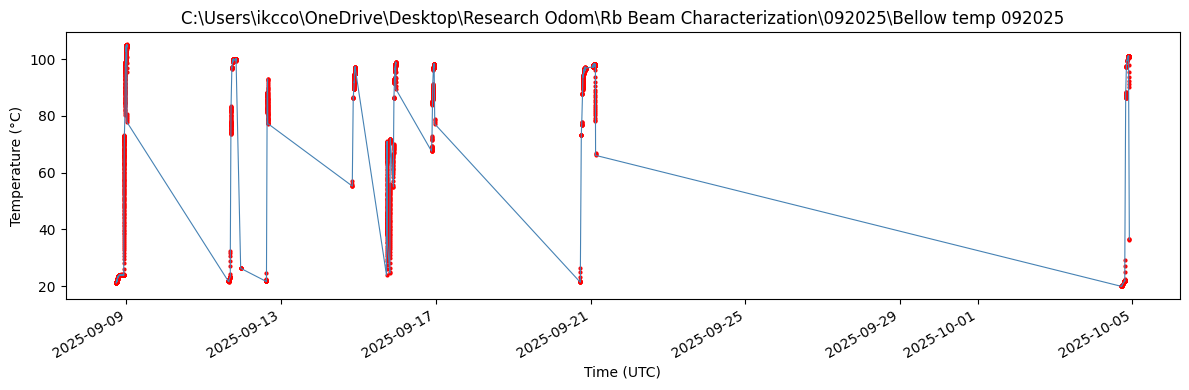

In [7]:
nozzle_temp = r"C:\Users\ikcco\OneDrive\Desktop\Research Odom\Rb Beam Characterization\092025\Nozzle Temp 092025.csv"
Rb_temp = r"C:\Users\ikcco\OneDrive\Desktop\Research Odom\Rb Beam Characterization\092025\Rb Temp 092025.csv"
bellow_temp = r"C:\Users\ikcco\OneDrive\Desktop\Research Odom\Rb Beam Characterization\092025\Bellow temp 092025.csv"

plot_temp_log(nozzle_temp)

plot_temp_log(Rb_temp)

plot_temp_log(bellow_temp)

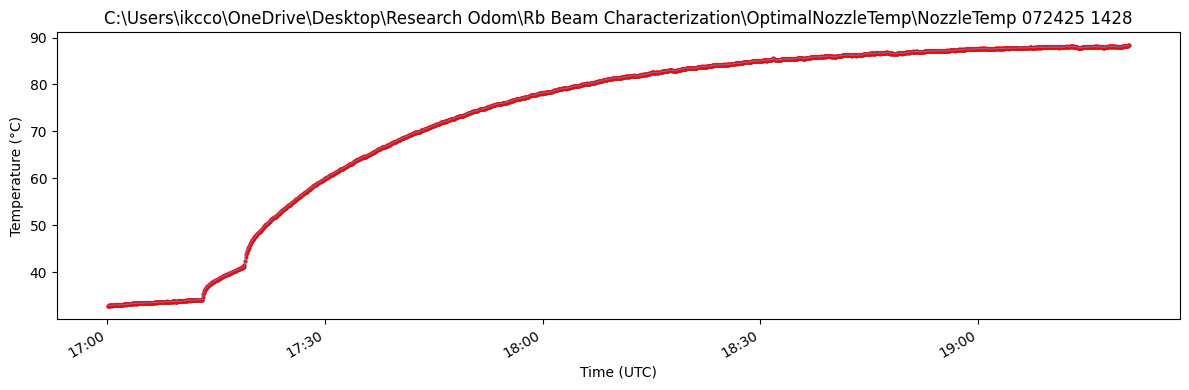

In [8]:

plot_temp_log(r"C:\Users\ikcco\OneDrive\Desktop\Research Odom\Rb Beam Characterization\OptimalNozzleTemp\NozzleTemp 072425 1428.csv")

In [9]:
def plot_temp_log_multi(filepath, column):
    """
    Parameters
    ----------
    column : str — one of 'Rb Reservoir', 'bellows', 'Nozzle'
    """
    df = pd.read_csv(filepath, usecols=['Time', column])
    df['Time'] = pd.to_datetime(df['Time'])
    df = df.dropna(subset=[column]).sort_values('Time')

    fig, ax = plt.subplots(figsize=(12, 4))
    ax.scatter(df['Time'], df[column], s=4, color='steelblue')

    ax.set_xlabel('Time')
    ax.set_ylabel('Temperature (°C)')
    ax.set_title(f"{filepath.split('/')[-1].replace('.csv', '')} — {column}")

    span = df['Time'].iloc[-1] - df['Time'].iloc[0]
    if span.days > 7:
        ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d'))
    elif span.days > 1:
        ax.xaxis.set_major_formatter(mdates.DateFormatter('%m-%d %H:%M'))
    else:
        ax.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))

    fig.autofmt_xdate()
    plt.tight_layout()
    plt.show()

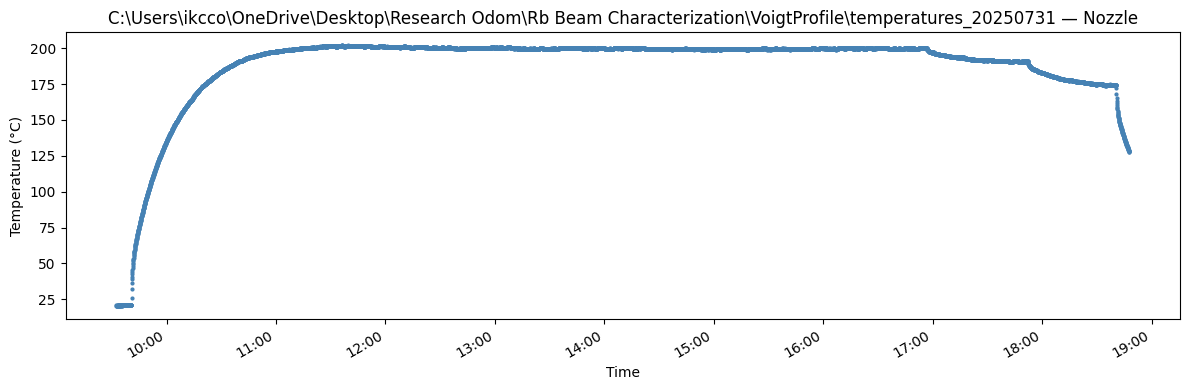

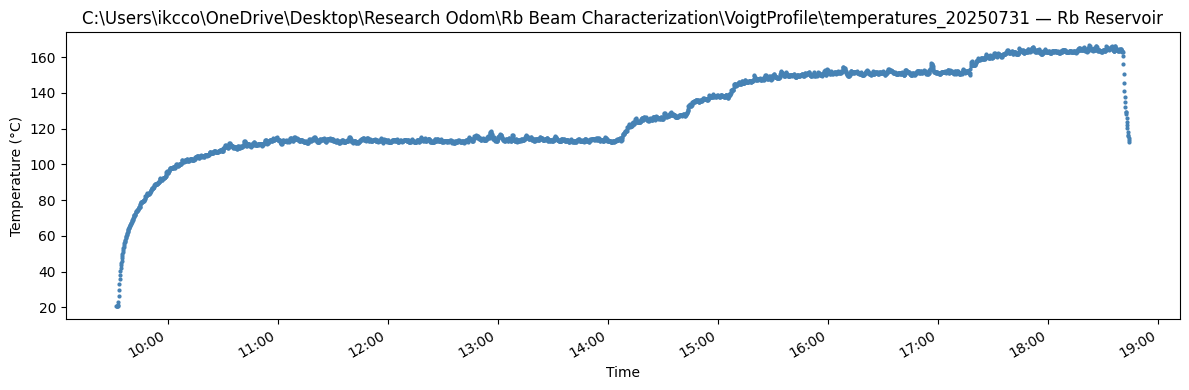

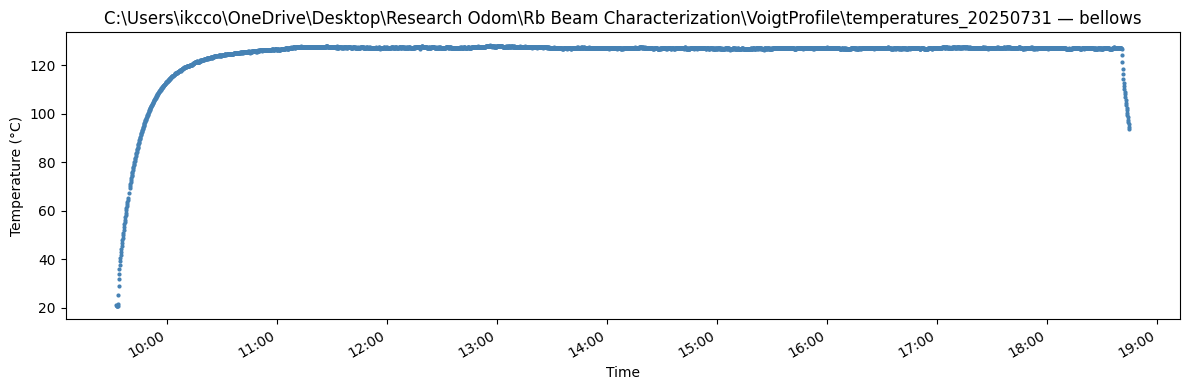

In [10]:
file_path = r"C:\Users\ikcco\OneDrive\Desktop\Research Odom\Rb Beam Characterization\VoigtProfile\temperatures_20250731.csv"
plot_temp_log_multi(file_path, column="Nozzle")
plot_temp_log_multi(file_path, column="Rb Reservoir")
plot_temp_log_multi(file_path, column="bellows")

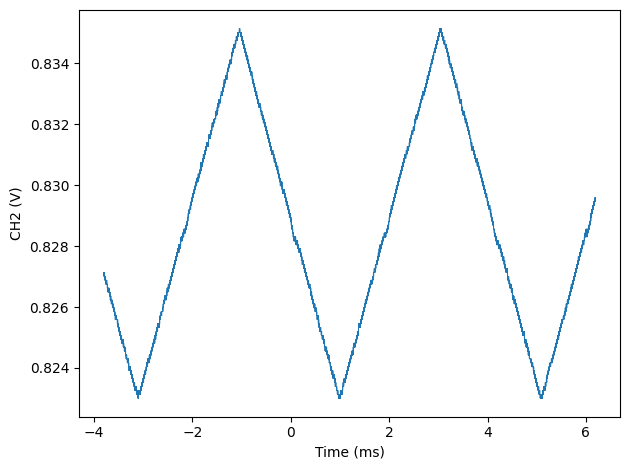

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

filepath = r"C:\Users\ikcco\OneDrive\Desktop\IsaacCross_Thesis_Stuff\Rb_beam_characterization\absorption_data\data_101225\Far\full2.csv"

# parse t0 and tInc from header
with open(filepath) as f:
    header = f.readline()

t0   = float(header.split("t0 = ")[1].split("s")[0])
tInc = float(header.split("tInc = ")[1].split("s")[0])

# load voltage column, skipping header
df = pd.read_csv(filepath, skiprows=1, header=None, usecols=[0])
CH2 = df[0].to_numpy()

t = t0 + np.arange(len(CH2)) * tInc

plt.figure()
plt.plot(t * 1000, CH2, linewidth=0.5)
plt.xlabel("Time (ms)")
plt.ylabel("CH2 (V)")
plt.tight_layout()
plt.show()

In [2]:
import pandas as pd
import numpy as np

filepath_in  = r"C:\Users\ikcco\OneDrive\Desktop\IsaacCross_Thesis_Stuff\Rb_beam_characterization\absorption_data\data_101225\Far\full2.csv"
filepath_out = r"C:\Users\ikcco\OneDrive\Desktop\IsaacCross_Thesis_Stuff\Rb_beam_characterization\absorption_data\data_101225\Far\full2converted.csv"

# parse t0 and tInc from header
with open(filepath_in) as f:
    header = f.readline()

t0   = float(header.split("t0 = ")[1].split("s")[0])
tInc = float(header.split("tInc = ")[1].split("s")[0])

# load voltage column
df   = pd.read_csv(filepath_in, skiprows=1, header=None, usecols=[0])
CH2  = df[0].to_numpy()
t    = t0 + np.arange(len(CH2)) * tInc

# save
df_out = pd.DataFrame({"Time(s)": t, "CH2(V)": CH2})
df_out.to_csv(filepath_out, index=False)
print(f"Saved → {filepath_out}")

Saved → C:\Users\ikcco\OneDrive\Desktop\IsaacCross_Thesis_Stuff\Rb_beam_characterization\absorption_data\data_101225\Far\full2converted.csv


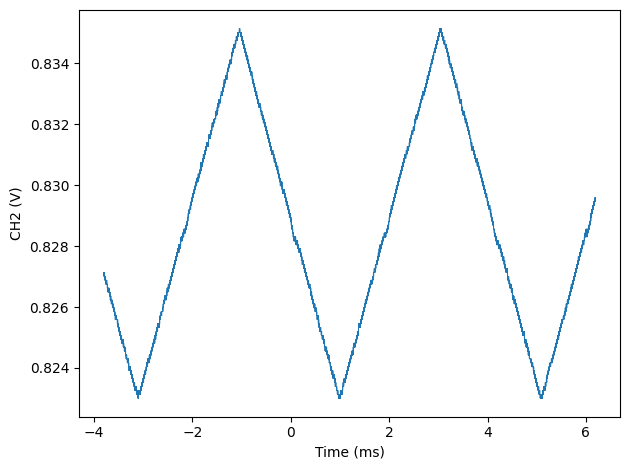

In [3]:
df = pd.read_csv(filepath_out)

plt.figure()
plt.plot(df["Time(s)"] * 1000, df["CH2(V)"], linewidth=0.5)
plt.xlabel("Time (ms)")
plt.ylabel("CH2 (V)")
plt.tight_layout()
plt.show()

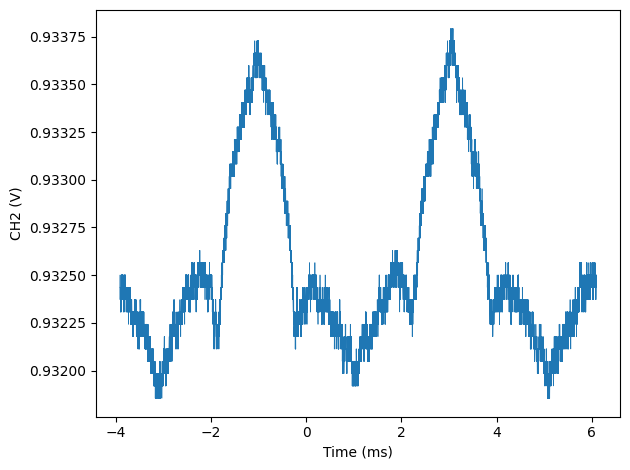

In [4]:
filepath = r"C:\Users\ikcco\OneDrive\Desktop\IsaacCross_Thesis_Stuff\Rb_beam_characterization\absorption_data\data_101225\RigolDS0converted.csv"

df = pd.read_csv(filepath)

plt.figure()
plt.plot(df["Time(s)"] * 1000, df["CH2(V)"], linewidth=0.5)
plt.xlabel("Time (ms)")
plt.ylabel("CH2 (V)")
plt.tight_layout()
plt.show()